# Lesson 1 — Features: turning requests into numbers

Lesson 1 — Features: turning requests into numbers
==================================================

GURU NOTE
---------
A model cannot read `GET /search?q=' OR 1=1--`. It reads *numbers*. So the very
first move in all of machine learning is to convert the messy real thing into a
fixed-length list of numbers — a "feature vector".

Your real repo does exactly this. The engine turns every request into 32 numbers
(open `../xorguard-ml/contract/supervised-v1.json` to see their names: sqli, xss,
rce, ..., entropy, path_len, ..., bias). This lesson builds a tiny 2-feature
version so you can SEE it, then scales the idea up to the real 32.

Two rules you will carry all course:
  * A **feature** is one number describing the input. Many features = a vector.
  * A **label** is the known correct answer. In xorguard: 1 = malicious, 0 = benign.

Run me:  python lessons/lesson_01_features.py

## Setup

These notebooks *import* the real code from `lessons/*.py` — one source of truth, no forked copies. This cell finds that folder.

In [1]:
import sys, pathlib
for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (base / 'lessons' / '_util.py').exists():
        sys.path.insert(0, str(base / 'lessons'))
        print('lessons on path:', base / 'lessons'); break
else:
    raise RuntimeError('Open this notebook inside the xorguard-ml-course folder.')

lessons on path: /Users/anil/Documents/developer/vscodeworkspaces/xordev/xorguard-ml-course/lessons


## The key code (shown live from the source file)

Read it, then copy any function into a new cell and tweak it — the originals live in `lessons/lesson_01_features.py`.

In [2]:
import inspect
from lesson_01_features import two_features, build_dataset
for fn in (two_features, build_dataset):
    print(inspect.getsource(fn)); print('-' * 72)

def two_features(text: str) -> np.ndarray:
    """Return [special_char_ratio, sqli_hits] for a string.

    Feature 1 - special_char_ratio: fraction of chars that are 'punctuation-ish'.
                Attacks are full of  ' " < > ; ( ) = -  ; normal text is not.
    Feature 2 - sqli_hits: how many classic SQLi tokens appear (crude on purpose).
    """
    if not text:
        return np.array([0.0, 0.0])
    specials = sum(c in "'\"<>;()=-/*|&$" for c in text)
    special_ratio = specials / len(text)

    lowered = text.lower()
    sqli_tokens = ["'", " or ", " and ", "union", "select", "--", "1=1", "#"]
    sqli_hits = sum(lowered.count(tok) for tok in sqli_tokens)
    # squash the raw count into roughly 0..1 so both features share a scale
    sqli_hits = min(1.0, sqli_hits / 4.0)
    return np.array([special_ratio, sqli_hits])

------------------------------------------------------------------------
def build_dataset():
    """Featurize both lists, stack into X (features) and y (labe

## A picture

A real plot (matplotlib) in place of the terminal's ASCII. Re-run after changing inputs to build intuition.

Matplotlib is building the font cache; this may take a moment.


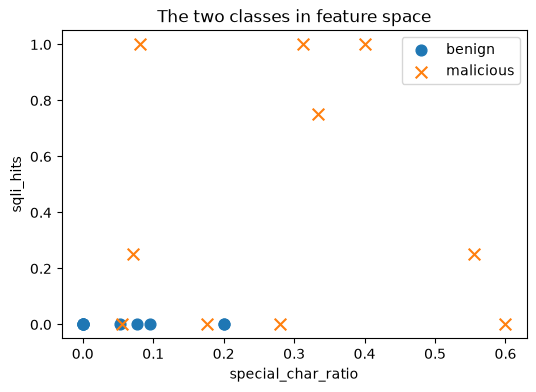

In [3]:
import matplotlib.pyplot as plt
from lesson_01_features import build_dataset
X, y = build_dataset()
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(X[y == 0, 0], X[y == 0, 1], marker='o', s=60, label='benign')
ax.scatter(X[y == 1, 0], X[y == 1, 1], marker='x', s=70, label='malicious')
ax.set_xlabel('special_char_ratio'); ax.set_ylabel('sqli_hits')
ax.set_title('The two classes in feature space'); ax.legend()
plt.show()

## Run the full narrated lesson

This executes the same walkthrough as `python lessons/lesson_01_features.py`, printing each step with its result.

In [4]:
from lesson_01_features import main
main()


══════════════════════════════════════════════════
Lesson 1 — Features: turning requests into numbers
══════════════════════════════════════════════════

▸ First, watch ONE request become numbers.
    text     : "' OR 1=1--"
    features : [special_ratio=0.400, sqli_hits=1.000]
    A human sees an attack. The model will only ever see those 2 numbers.

▸ Now featurize a benign one for contrast.
    text     : 'red dress size 10'
    features : [special_ratio=0.000, sqli_hits=0.000]

▸ Build the whole tiny dataset: X = features, y = labels (1=mal, 0=benign).
    X shape = (20, 2)  (rows = requests, columns = features)
    y shape = (20,)  (one label per row)
    positives (attacks) = 10, negatives (benign) = 10

▸ The key insight — plot the two classes in feature space.
    If the two clouds separate, a model can draw a boundary between them.
    THIS is what 'learnable' looks like. Keep this picture in your head.

   sqli_hits ↑   ( # = malicious   . = benign )
      |       #         

## Exercises

Try these in new cells below. Worked answers are in `solutions/lesson_01_solution.py`.

```
1. Add a THIRD feature to two_features(): `length` = min(1.0, len(text)/40).
   Does it help separate the classes? Print it for a few strings.

2. Add a benign string that FOOLS the current features — something that scores
   high on special_char_ratio but is actually harmless (hint: a math
   expression like "(3*4)=12"). This is a "hard negative", and Lesson 6 +
   hardneg.py in the repo are all about these.

3. Write featurize_like_engine(text) that returns a length-3 vector
   [special_ratio, sqli_hits, xss_hits] where xss_hits counts "<script",
   "onerror", "onload", "<svg". Featurize "<svg onload=alert(1)>" and confirm
   the xss feature lights up but sqli stays ~0.
```

In [5]:
# your work here
